# 04 · Modelos PyTorch

Dois modelos, ambos prevendo as **variações** da cota nos 3 horizontes de uma vez (saída com 3 valores):

- **MLP** sobre as features tabulares;
- **GRU** sobre as últimas 48 h de todas as variáveis.

Entradas e alvos são padronizados com média/desvio **do treino**. A validação serve só para o *early stopping*; o teste (eventos extremos) não é usado no treino.
Para execução rápida de teste: `CAPSTONE_FAST=1` (poucas épocas).

**Limites contra extrapolação:** as entradas (inclusive as janelas da GRU) e a variação prevista ficam na faixa do treino
+ margem (`config.CLIP_MARGIN`). A previsão sem limites é salva junto, para o notebook 05 medir o efeito.

In [1]:
import os, sys
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"   # esconde a GPU; precisa vir antes de importar o torch
sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data, features, metrics, pipeline
plt.rcParams["figure.figsize"] = (11, 3.4)
plt.rcParams["axes.grid"] = True

import torch, json
from src import models

FAST = os.environ.get("CAPSTONE_FAST") == "1"
EPOCHS = 3 if FAST else 80
N_SEEDS = 1 if FAST else 3          # média de várias sementes deixa o resultado mais estável
DEVICE = torch.device("cpu")
print("dispositivo:", DEVICE, "| épocas:", EPOCHS, "| sementes:", N_SEEDS)

dispositivo: cpu | épocas: 80 | sementes: 3


In [2]:
def treinar_conjunto(make_model, Xtr, Ytr, Xva, Yva, Xpred, nome, alvo, epochs=EPOCHS, n_seeds=N_SEEDS, **fit_kw):
    """Treina n_seeds modelos. Xpred: lista de matrizes a prever (ex.: entradas limitadas e livres).
    Devolve a lista das médias das previsões (escala padronizada) + histórico da 1ª semente."""
    preds, hist0 = [[] for _ in Xpred], None
    for s in range(n_seeds):
        models.set_seed(config.RANDOM_STATE + s)
        m = make_model()
        m, hist = models.fit(m, Xtr, Ytr, Xva, Yva, epochs=epochs, device=DEVICE, verbose=(s == 0), **fit_kw)
        torch.save(m.state_dict(), config.MODELS / f"{nome}_{alvo}_seed{s}.pt")
        for k, X in enumerate(Xpred):
            preds[k].append(models.predict(m, X, device=DEVICE))
        hist0 = hist0 or hist
    return [np.mean(p, axis=0) for p in preds], hist0

In [3]:
panel = pipeline.load_panel()
resultados = {}
historicos = {}

for alvo in config.TARGETS:
    if f"cota_{alvo}" not in panel:
        continue
    print(f"\n################ {config.STATIONS[alvo]['nome']} ({alvo}) ################")

    # ---------- MLP (tabular). Entradas limitadas à faixa do treino; no treino isso não muda nada.
    P = features.build_tabular(panel, alvo)
    tr, va, te = (P.masks[k] for k in ("train", "val", "test"))
    Xs, _ = features.nn_inputs(P, clip=True)
    Xs_livre, _ = features.nn_inputs(P, clip=False)
    sy = features.Scaler.fit(P.Y[tr])
    Ys = sy.transform(P.Y)
    (pred_s, pred_s_livre), historicos[("mlp", alvo)] = treinar_conjunto(
        lambda: models.MLP(Xs.shape[1], Ys.shape[1], hidden=(128, 64), dropout=0.1),
        Xs[tr], Ys[tr], Xs[va], Ys[va], [Xs, Xs_livre], "mlp", alvo)
    pred_abs_mlp = P.base[:, None] + features.limit_delta(P, sy.inverse(pred_s))
    pipeline.save_predictions("mlp", alvo, P, pred_abs_mlp, P.base[:, None] + sy.inverse(pred_s_livre))

    # ---------- GRU (sequências)
    S = features.build_sequences(panel, alvo)
    tr2, va2 = S.masks["train"], S.masks["val"]
    Xq, _ = features.nn_inputs(S, clip=True)
    Xq_livre, _ = features.nn_inputs(S, clip=False)
    sys_ = features.Scaler.fit(S.Y[tr2])
    Yq = sys_.transform(S.Y)
    (pred_s2, pred_s2_livre), historicos[("gru", alvo)] = treinar_conjunto(
        lambda: models.GRUNet(Xq.shape[2], Yq.shape[1], hidden=64, num_layers=1, dropout=0.1),
        Xq[tr2], Yq[tr2], Xq[va2], Yq[va2], [Xq, Xq_livre], "gru", alvo)
    pred_abs_gru = S.base[:, None] + features.limit_delta(S, sys_.inverse(pred_s2))
    pipeline.save_predictions("gru", alvo, S, pred_abs_gru, S.base[:, None] + sys_.inverse(pred_s2_livre))

    # ---------- métricas no teste
    tabs = []
    for nome, PP, pa in (("mlp", P, pred_abs_mlp), ("gru", S, pred_abs_gru)):
        m = PP.masks["test"]
        if m.sum() == 0:
            continue
        t = metrics.summary_table(PP.Yabs[m], pa[m], PP.base[m], PP.horizons)
        t.insert(0, "modelo", nome); tabs.append(t.reset_index())
    if tabs:
        resultados[alvo] = pd.concat(tabs).set_index(["modelo", "horizonte_h"])
        display(resultados[alvo])

[clean_panel] dados a partir de 2018-05-01; ajustes: {'cota_86510000': '2 h < 0 cm -> NaN', 'cota_86720000': '303 h < 0 cm -> NaN'}
[pipeline] cenário: com_imerg | colunas: 12

################ Muçum (86510000) ################
[features] colunas removidas por pouca cobertura no treino: {'cota_86472600': '0%', 'chuva_86472600': '0%'}


epoch   1 | treino 0.4516 | validação 0.4020


epoch   5 | treino 0.1912 | validação 0.3298


epoch  10 | treino 0.1478 | validação 0.3153


epoch  15 | treino 0.1306 | validação 0.3351


epoch  20 | treino 0.1185 | validação 0.2850


... (16 outputs left out)

epoch  20 | treino 0.0597 | validação 0.3855


epoch  25 | treino 0.0536 | validação 0.3793


epoch  30 | treino 0.0484 | validação 0.3875
early stopping no epoch 30 (melhor validação 0.3717)


n  RMSE_cm  MAE_cm    NSE  skill_vs_persist
modelo horizonte_h                                                 
mlp    6            24923   16.337   9.148  0.990             0.807
       8            24894   21.343  11.948  0.984             0.791
       12           24854   34.126  17.917  0.958             0.708
gru    6            25384   23.589  15.267  0.982             0.648
       8            25341   28.200  16.967  0.974             0.676
       12           25297   38.354  20.498  0.952             0.651

## Curvas de treino (perda padronizada)

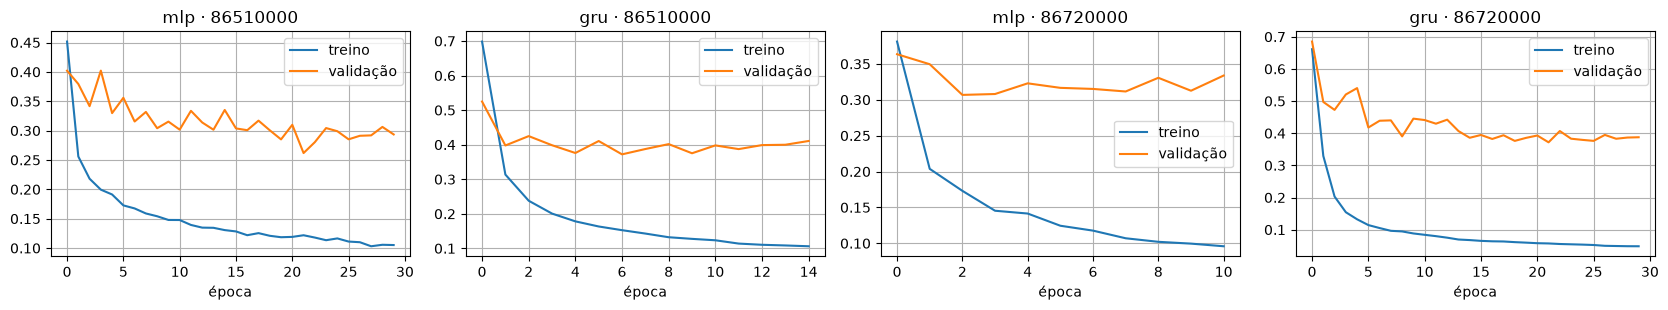

In [4]:
fig, axes = plt.subplots(1, len(historicos), figsize=(4.2 * len(historicos), 3.2), squeeze=False)
for ax, ((nome, alvo), h) in zip(axes[0], historicos.items()):
    ax.plot(h["train"], label="treino"); ax.plot(h["val"], label="validação")
    ax.set_title(f"{nome} · {alvo}"); ax.set_xlabel("época"); ax.legend()
plt.tight_layout(); plt.show()

**Atenção ao interpretar:** o MLP e a GRU usam `skill_vs_persist` como o baseline: se ficarem abaixo do gradient boosting do notebook 03, isso também é um resultado válido.
Redes recorrentes costumam render mais com dados de **muitas bacias**; com uma bacia só, árvores e modelos simples frequentemente competem bem.
Os pesos ficam em `outputs/models/`.